# 04 · Portfolio construction, risk and implementation

**Who this is for:** portfolio managers and risk managers. Every construction layer is a configuration switch, and all are causal:
- legs and allocators;
- tranches;
- the beta budget versus beta neutrality;
- position caps;
- volatility targeting;
- trading costs, short-borrow fees and execution delay.

The signal is held fixed throughout, so every difference below comes from construction alone.

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")
from fmflow.analytics.metrics import perf_stats, capm, conditional_betas, lo_adjusted_sharpe
from fmflow.backtest.engine import annual_turnover, breakeven_cost_bps, cost_sensitivity
mkt = out.returns.mean(axis=1)
def row(o):
    n = o.net_returns.loc[EV]; s = perf_stats(n); c = capm(n, mkt.loc[EV])
    return {"Sharpe": s["Sharpe"], "Calmar": s["Calmar"], "MaxDD": s["Max drawdown"], "vol": s["Ann. vol"], "beta": c["beta"],
            "alpha t": c["alpha_t"], "turnover x/yr": annual_turnover(o.result.traded.loc[EV])}

30 stocks, 899 sessions, 2,363 accepted ratings


## 1. The construction menu

The presets are documented in `StrategyConfig`. Each one is a single line, and the signal is identical in all of them.

In [3]:
variants = {
    "FMF-N (leg fraction 0.4, IV-GJR, 42 tranches)": CFG,
    "equal weights": CFG.with_(allocator="EW"),
    "21 tranches": CFG.with_(tranche_period=21), "63 tranches": CFG.with_(tranche_period=63),
    "beta-neutral legs": CFG.with_(neutralize="beta"),
    "beta budget +0.2 (FMF-B20)": CFG.with_(net_exposure=0.2),
    "position cap 6%": CFG.with_(max_weight=0.06),
    "vol target 10%": CFG.with_(vol_target=0.10, max_leverage=2.0),
}
runs = {k: run_strategy(P, R, v, sig_vol=SIG) for k, v in variants.items()}
display(pd.DataFrame({k: row(o) for k, o in runs.items()}).T)

,Sharpe,Calmar,MaxDD,vol,beta,alpha t,turnover x/yr
"FMF-N (leg fraction 0.4, IV-GJR, 42 tranches)",1.046,1.319,-0.080,0.100,-0.025,2.039,2.743
equal weights,1.046,1.454,-0.082,0.114,-0.034,2.025,2.571
21 tranches,0.757,0.843,-0.088,0.101,-0.039,1.633,4.089
63 tranches,1.006,1.314,-0.074,0.097,-0.017,1.877,2.253
beta-neutral legs,1.068,1.275,-0.083,0.099,0.029,2.083,2.751
beta budget +0.2 (FMF-B20),1.487,2.428,-0.065,0.103,0.161,2.090,2.721
position cap 6%,0.975,1.292,-0.071,0.094,-0.033,1.896,1.846
vol target 10%,1.111,1.681,-0.071,0.106,-0.046,2.206,3.900


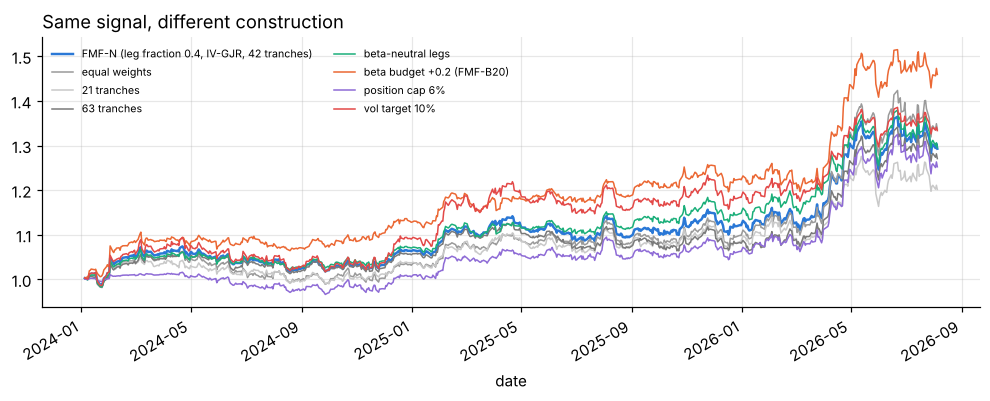

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for (k, o), c in zip(runs.items(), [BLUE, GREY, "#c9c9c9", "#7a7a7a", GREEN, ORANGE, "#8e6bd6", RED]):
    (1 + o.net_returns.loc[EV]).cumprod().plot(ax=ax, label=k, color=c, lw=1.6 if k.startswith("FMF") else 1.0)
ax.legend(frameon=False, fontsize=7, ncol=2); ax.set_title("Same signal, different construction", loc="left"); plt.show()

**Position cap:** A 6% cap binds on this universe. A leg usually holds 6 to 8 names (the median is 7), and spending its 50% budget would need at least 0.5 / 0.06 ≈ 8.3 names. The cap is a hard limit, so such a leg holds 6% per name and the rest of its budget stays uninvested: over the evaluation window the held book's gross averages about 0.75 instead of 1. Most of the lower Sharpe ratio and turnover comes from that smaller book. Choose a cap with the leg size in mind (cap ≥ 0.5 / names per leg keeps the full budget).

## 2. Beta is a decision

A dollar-neutral book is not automatically beta-neutral. Look at the ex-ante beta of the book through time, and at its up-market and down-market betas: a "market-neutral" book that is long beta in sell-offs is a hidden risk.

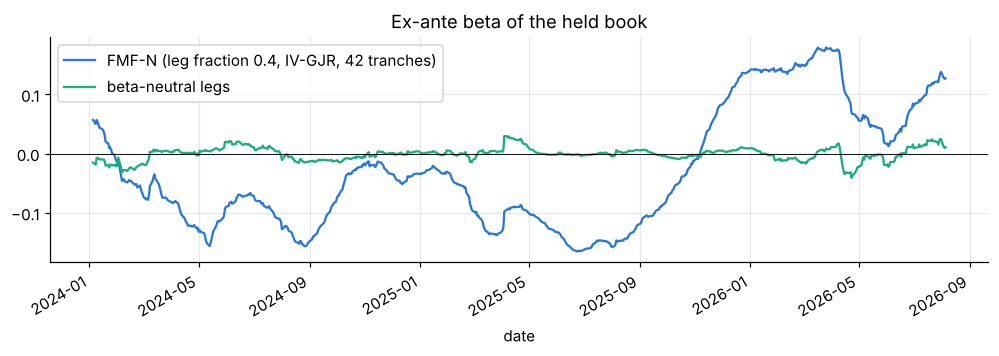

,beta_up,beta_down,t_up,t_down,mean_in_worst_market_decile_weeks,corr_in_worst_decile
"FMF-N (leg fraction 0.4, IV-GJR, 42 tranches)",-0.037,-0.013,-0.454,-0.251,0.002,-0.136
beta-neutral legs,-0.008,0.065,-0.127,1.373,-0.001,0.310


In [5]:
from fmflow.portfolio.construction import rolling_betas
b = rolling_betas(out.returns)
exb = pd.DataFrame({k: (runs[k].weights * b).sum(axis=1) for k in ("FMF-N (leg fraction 0.4, IV-GJR, 42 tranches)", "beta-neutral legs")}).loc[EV]
exb.plot(figsize=(11, 3), color=[BLUE, GREEN], title="Ex-ante beta of the held book"); plt.axhline(0, color="k", lw=0.6); plt.show()
display(pd.DataFrame({k: conditional_betas(runs[k].net_returns.loc[EV], mkt.loc[EV]) for k in exb.columns}).T)

## 3. Implementation realism

Several things can each move the result:
- a one- or two-session execution delay;
- short-borrow fees of 0 to 200 bp a year;
- trading costs of 0 to 30 bp per unit traded.

The **breakeven cost** is the cost per unit traded at which the net mean return reaches zero. It is the cleanest single capacity diagnostic you can compute without volume data.

In [6]:
g = cost_sensitivity(out.weights, out.returns, cost_grid=(0, 5, 10, 20, 30), borrow_grid=(0, 50, 100, 200), execution_lags=(0, 1, 2), window=EV)
for lag in (0, 1, 2):
    print(f"execution delay {lag} session(s): Sharpe by cost (rows, bp) x borrow (columns, bp p.a.)")
    display(g.query("execution_lag == @lag").pivot(index="cost_bps", columns="borrow_bps", values="Sharpe"))
print(f"breakeven cost: {breakeven_cost_bps(out.result, EV.start, EV.stop):.0f} bp per unit traded "
      f"(turnover {annual_turnover(out.result.traded.loc[EV]):.1f}x per year)")
print("Lo (2002) autocorrelation-adjusted Sharpe:", {k: round(v, 3) for k, v in lo_adjusted_sharpe(out.net_returns.loc[EV]).items()})

execution delay 0 session(s): Sharpe by cost (rows, bp) x borrow (columns, bp p.a.)


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.073,1.050,1.026,0.980
5,1.046,1.023,0.999,0.952
10,1.019,0.995,0.972,0.925
20,0.964,0.941,0.917,0.870
30,0.909,0.886,0.862,0.816


execution delay 1 session(s): Sharpe by cost (rows, bp) x borrow (columns, bp p.a.)


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.088,1.064,1.041,0.994
5,1.060,1.037,1.014,0.967
10,1.033,1.010,0.986,0.939
20,0.978,0.955,0.932,0.885
30,0.924,0.900,0.877,0.830


execution delay 2 session(s): Sharpe by cost (rows, bp) x borrow (columns, bp p.a.)


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.097,1.074,1.051,1.004
5,1.070,1.047,1.023,0.976
10,1.043,1.019,0.996,0.949
20,0.988,0.965,0.941,0.894
30,0.933,0.910,0.886,0.840


breakeven cost: 197 bp per unit traded (turnover 2.7x per year)
Lo (2002) autocorrelation-adjusted Sharpe: {'sharpe_naive': 1.046, 'sharpe_lo': 1.061, 'rho_1': 0.037, 'sum_rho_1_to_L': -0.014}


## 4. A conservative implementation preset

`StrategyConfig.conservative_costs()` charges 10 bp per unit traded and a 100 bp borrow fee, and trades one session late. Use it as the default for anything you show to an investment committee.

In [7]:
cons = run_strategy(P, R, StrategyConfig.conservative_costs().with_(k=None, leg_fraction=0.4), sig_vol=SIG)
display(pd.DataFrame({"FMF-N (5 bp, no borrow, close)": row(out), "conservative": row(cons)}).T)

,Sharpe,Calmar,MaxDD,vol,beta,alpha t,turnover x/yr
"FMF-N (5 bp, no borrow, close)",1.046,1.319,-0.080,0.100,-0.025,2.039,2.743
conservative,0.986,1.247,-0.079,0.101,-0.024,1.918,2.746
